In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["font.size"] = 12

df = pd.read_csv('Kaggle-data.csv', low_memory=False)

if 'Unnamed: 57' in df.columns:
    df = df.drop(columns=['Unnamed: 57'])

df = df.dropna()

print("Датасет успешно загружен. Размерность:", df.shape)

Датасет успешно загружен. Размерность: (216351, 57)


/var/folders/ht/3zxlzwj961712fdtmv35tw0c0000gn/T/ipykernel_2863/4079480929.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(x='legitimate', data=df, palette=['#e74c3c', '#2ecc71'])


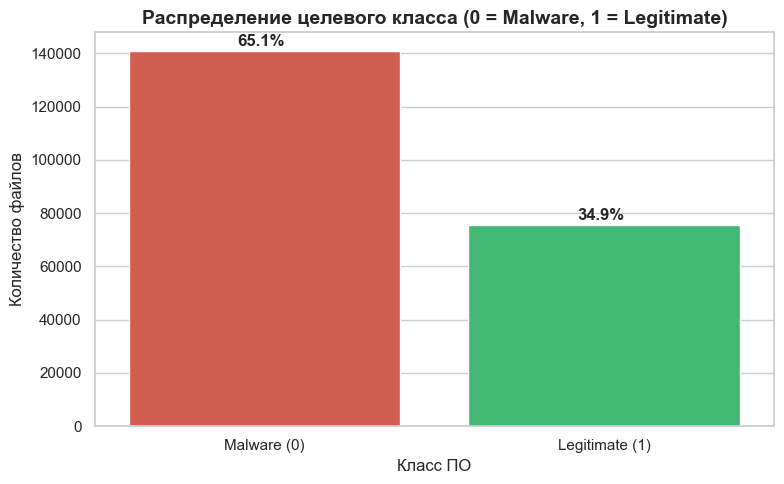

In [3]:
plt.figure(figsize=(8, 5))
ax = sns.countplot(x='legitimate', data=df, palette=['#e74c3c', '#2ecc71'])

plt.title('Распределение целевого класса (0 = Malware, 1 = Legitimate)', fontsize=14, fontweight='bold')
plt.xlabel('Класс ПО')
plt.ylabel('Количество файлов')
plt.xticks(ticks=[0, 1], labels=['Malware (0)', 'Legitimate (1)'])

total = len(df)
for p in ax.patches:
    percentage = f'{100 * p.get_height() / total:.1f}%'
    x = p.get_x() + p.get_width() / 2 - 0.08
    y = p.get_height() + 2000
    ax.annotate(percentage, (x, y), fontweight='bold')

plt.tight_layout()
plt.show()

Вывод по Графику 1: Анализ целевой переменной показывает, что выборка содержит 65.1% вредоносных программ (140,849 объектов) и 34.9% легитимного ПО (75,503 объекта). Присутствует умеренный дисбаланс классов (соотношение ~1.86:1). Это указывает на необходимость использования метрик $F1$-score и ROC-AUC/PR-AUC для объективной оценки качества модели вместо метрики Accuracy.

/var/folders/ht/3zxlzwj961712fdtmv35tw0c0000gn/T/ipykernel_2863/3346553304.py:4: FutureWarning: 

`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an error in seaborn v0.14.0; please update your code.

  sns.kdeplot(data=df[df['legitimate'] == 0]['SectionsMeanEntropy'],
/var/folders/ht/3zxlzwj961712fdtmv35tw0c0000gn/T/ipykernel_2863/3346553304.py:7: FutureWarning: 

`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an error in seaborn v0.14.0; please update your code.

  sns.kdeplot(data=df[df['legitimate'] == 1]['SectionsMeanEntropy'],


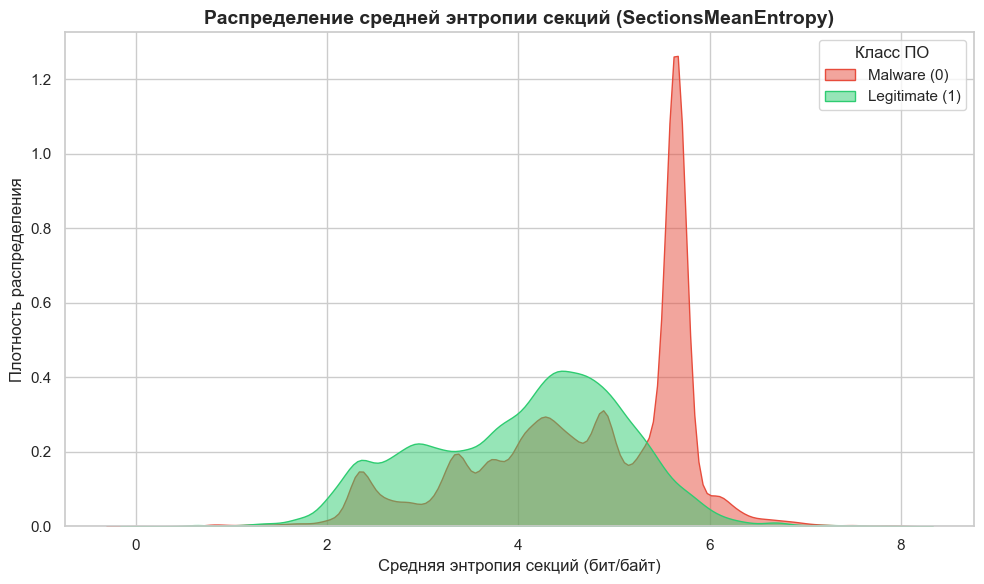

In [4]:
plt.figure(figsize=(10, 6))

sns.kdeplot(data=df[df['legitimate'] == 0]['SectionsMeanEntropy'], 
            shade=True, color='#e74c3c', label='Malware (0)', alpha=0.5)

sns.kdeplot(data=df[df['legitimate'] == 1]['SectionsMeanEntropy'], 
            shade=True, color='#2ecc71', label='Legitimate (1)', alpha=0.5)

plt.title('Распределение средней энтропии секций (SectionsMeanEntropy)', fontsize=14, fontweight='bold')
plt.xlabel('Средняя энтропия секций (бит/байт)')
plt.ylabel('Плотность распределения')
plt.legend(title='Класс ПО')

plt.tight_layout()
plt.show()

Вывод по Графику 2: График плотности распределения энтропии показывает явное разделение классов. Вредоносное ПО (Malware) имеет выраженный пик в области высокой энтропии ($> 6.5$ бит/байт), что свидетельствует о массовом использовании упаковщиков (packers), крипторов и сжатия для скрытия вредоносного кода от антивирусных систем. Легитимное ПО (Legitimate), напротив, имеет более сглаженное распределение со средними значениями энтропии в районе $4.5–5.5$. Этот признак является одним из важнейших для классификатора.

/var/folders/ht/3zxlzwj961712fdtmv35tw0c0000gn/T/ipykernel_2863/2964122591.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='legitimate', y='ImportsNbDLL', data=df[df['ImportsNbDLL'] <= 30], palette=['#e74c3c', '#2ecc71'])


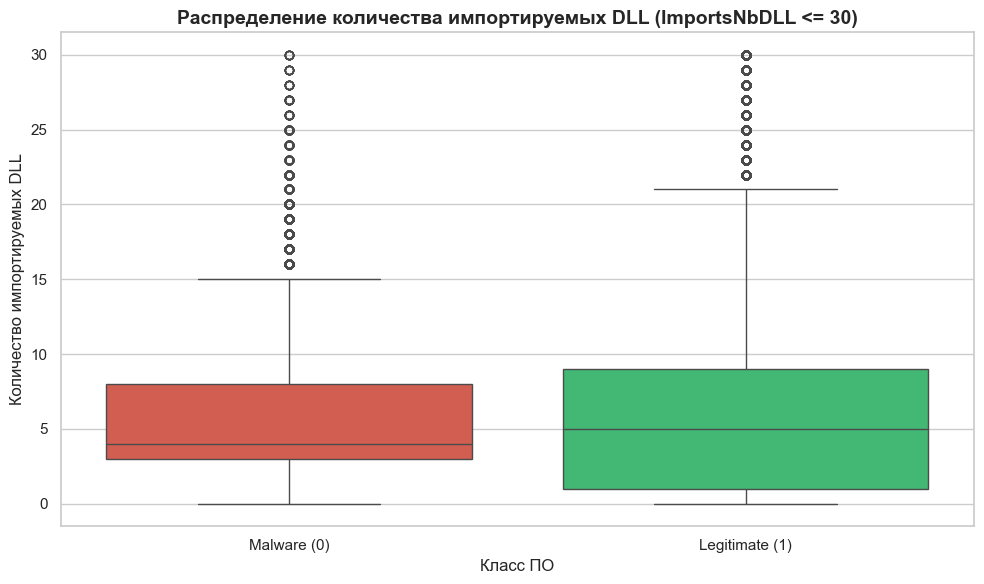

In [5]:
plt.figure(figsize=(10, 6))

sns.boxplot(x='legitimate', y='ImportsNbDLL', data=df[df['ImportsNbDLL'] <= 30], palette=['#e74c3c', '#2ecc71'])

plt.title('Распределение количества импортируемых DLL (ImportsNbDLL <= 30)', fontsize=14, fontweight='bold')
plt.xlabel('Класс ПО')
plt.ylabel('Количество импортируемых DLL')
plt.xticks(ticks=[0, 1], labels=['Malware (0)', 'Legitimate (1)'])

plt.tight_layout()
plt.show()

Вывод по Графику 3: Анализ количества подключенных динамических библиотек (DLL) показывает различия в структуре программ. Вредоносное ПО часто стремится либо снизить число импортируемых DLL (используя динамическую загрузку функций через LoadLibrary/GetProcAddress для обхода статического анализа), либо содержит аномально высокие значения из-за искусственного замусоривания таблицы импортов. Легитимное ПО имеет более стабильную медиану и предсказуемый межквартильный размах.

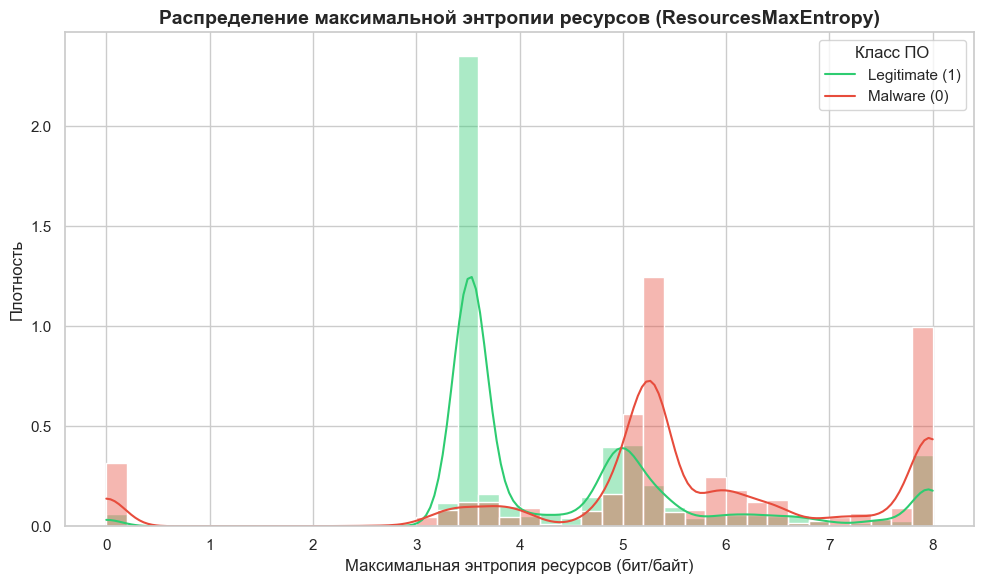

In [6]:
plt.figure(figsize=(10, 6))

sns.histplot(data=df, x='ResourcesMaxEntropy', hue='legitimate', 
             stat="density", common_norm=False, kde=True, 
             bins=40, palette=['#e74c3c', '#2ecc71'], alpha=0.4)

plt.title('Распределение максимальной энтропии ресурсов (ResourcesMaxEntropy)', fontsize=14, fontweight='bold')
plt.xlabel('Максимальная энтропия ресурсов (бит/байт)')
plt.ylabel('Плотность')
plt.legend(title='Класс ПО', labels=['Legitimate (1)', 'Malware (0)'])

plt.tight_layout()
plt.show()

Вывод по Графику 4: Распределение максимальной энтропии ресурсов демонстрирует выраженную асимметрию между классами. У вредоносного ПО (Malware) наблюдается высокий пик в области $\ge 7.0$ бит/байт (медиана $5.32$, 75%-квантиль $6.90$), что объясняется сокрытием зашифрованного кода или упакованных DLL внутри ресурсов PE-файла. У легитимных программ медианная энтропия ресурсов составляет всего $3.59$, так как там обычно хранятся стандартные не зашифрованные ресурсы (иконки, конфигурации).

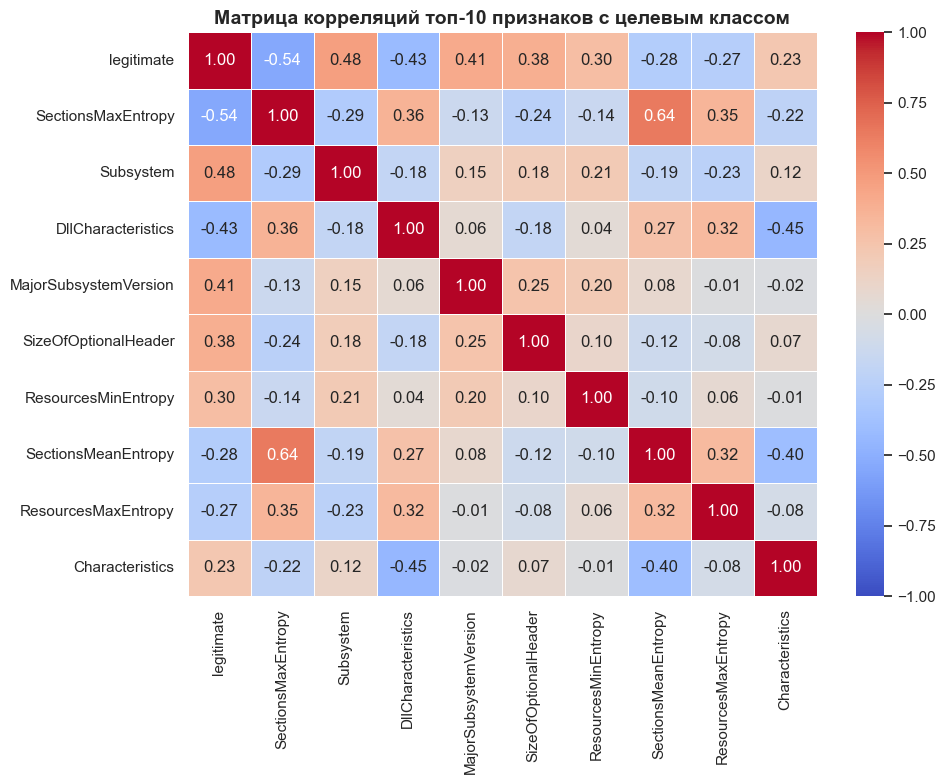

In [7]:
plt.figure(figsize=(10, 8))

top_corr_features = [
    'legitimate', 'SectionsMaxEntropy', 'Subsystem', 'DllCharacteristics', 
    'MajorSubsystemVersion', 'SizeOfOptionalHeader', 'ResourcesMinEntropy', 
    'SectionsMeanEntropy', 'ResourcesMaxEntropy', 'Characteristics'
]

corr_matrix = df[top_corr_features].corr()

sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, linewidths=0.5)

plt.title('Матрица корреляций топ-10 признаков с целевым классом', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

Вывод по Графику 5: Матрица корреляций демонстрирует наиболее значимые статические признаки PE-заголовков. Максимальную отрицательную корреляцию с легитимностью демонстрируют SectionsMaxEntropy ($-0.54$) и DllCharacteristics ($-0.43$), подтверждая, что высокая энтропия и специфические флаги DLL свойственны вредоносному ПО. В то же время параметры Subsystem ($+0.48$) и MajorSubsystemVersion ($+0.41$) положительно коррелируют с легитимными файлами. Высокая корреляция между SectionsMeanEntropy и SectionsMaxEntropy ($0.64$) указывает на наличие линейной зависимости, которую следует учитывать при выборе моделей.

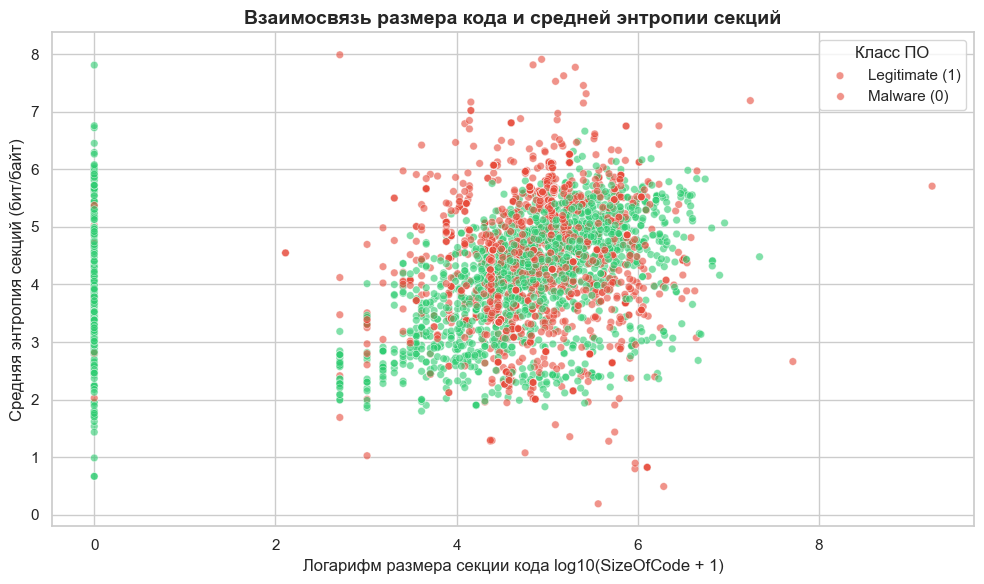

In [8]:
plt.figure(figsize=(10, 6))

sample_df = df.sample(n=5000, random_state=42).copy()
sample_df['log_SizeOfCode'] = np.log10(sample_df['SizeOfCode'] + 1)

sns.scatterplot(
    data=sample_df, 
    x='log_SizeOfCode', 
    y='SectionsMeanEntropy', 
    hue='legitimate', 
    palette=['#e74c3c', '#2ecc71'], 
    alpha=0.6, 
    s=30
)

plt.title('Взаимосвязь размера кода и средней энтропии секций', fontsize=14, fontweight='bold')
plt.xlabel('Логарифм размера секции кода log10(SizeOfCode + 1)')
plt.ylabel('Средняя энтропия секций (бит/байт)')
plt.legend(title='Класс ПО', labels=['Legitimate (1)', 'Malware (0)'])

plt.tight_layout()
plt.show()

Вывод по Графику 6: Диаграмма рассеяния наглядно демонстрирует кластеризацию объектов в двумерном пространстве признаков. Вредоносное ПО (Malware) концентрируется в верхней части графика (высокая энтропия $\ge 5.0$) при относительно небольших или средних размерах исполняемого кода. Легитимное ПО равномерно распределено в области более низкой энтропии ($2.5–4.5$) и охватывает широкий спектр объемов кода. Это подтверждает, что комбинация объемных и энтропийных характеристик образует эффективный разделяющий гиперпространственный класс для линейных и древовидных моделей.

In [9]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix, f1_score

# 1. Отбор числовых признаков (исключаем текстовые ID, md5 и нечисловые поля)
X = df.select_dtypes(include=[np.number]).drop(columns=['legitimate'])
y = df['legitimate']

# 2. Разделение на обучающую (80%) и тестовую (20%) выборки с сохранением пропорций классов
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 3. Масштабирование признаков
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 4. Обучение Baseline-модели
baseline_model = LogisticRegression(max_iter=1000, random_state=42)
baseline_model.fit(X_train_scaled, y_train)

# 5. Оценка качества
y_pred = baseline_model.predict(X_test_scaled)
y_proba = baseline_model.predict_proba(X_test_scaled)[:, 1]

# Расчет ключевых метрик
tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
fpr = fp / (fp + tn)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_proba)

print(f"=== РЕЗУЛЬТАТЫ BASELINE-МОДЕЛИ ===")
print(f"F1-Score: {f1:.4f}")
print(f"ROC-AUC:  {roc_auc:.4f}")
print(f"False Positive Rate (FPR): {fpr * 100:.2f}%")
print("\nМатрица ошибок (Confusion Matrix):")
print(f"True Negative (Malware корректно): {tn}")
print(f"False Positive (Ложная тревога):   {fp}")
print(f"False Negative (Пропущен вредонос): {fn}")
print(f"True Positive (Legitimate корректно): {tp}")

=== РЕЗУЛЬТАТЫ BASELINE-МОДЕЛИ ===
F1-Score: 0.9810
ROC-AUC:  0.9960
False Positive Rate (FPR): 0.98%

Матрица ошибок (Confusion Matrix):
True Negative (Malware корректно): 27893
False Positive (Ложная тревога):   277
False Negative (Пропущен вредонос): 295
True Positive (Legitimate корректно): 14806


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/utils/_plotting.py:175: FutureWarning: `**kwargs` is deprecated and will be removed in 1.9. Pass all matplotlib arguments to `curve_kwargs` as a dictionary instead.
  warnings.warn(


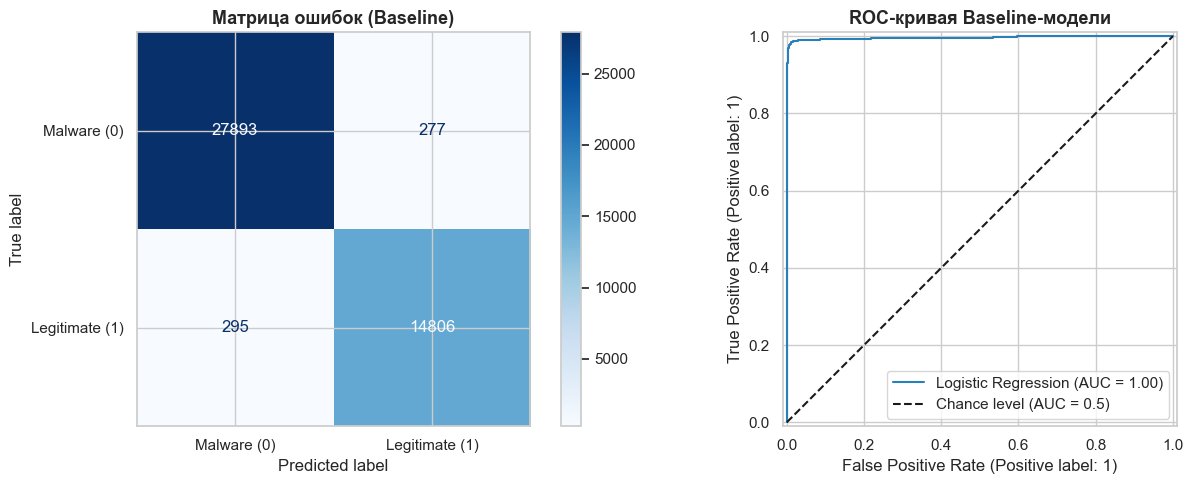

In [10]:
from sklearn.metrics import RocCurveDisplay, ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. График матрицы ошибок
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Malware (0)', 'Legitimate (1)'])
disp.plot(ax=axes[0], cmap='Blues', values_format='d')
axes[0].set_title('Матрица ошибок (Baseline)', fontsize=13, fontweight='bold')

# 2. График ROC-кривой
RocCurveDisplay.from_predictions(y_test, y_proba, ax=axes[1], color='#2980b9', name='Logistic Regression')
axes[1].plot([0, 1], [0, 1], 'k--', label='Chance level (AUC = 0.5)')
axes[1].set_title('ROC-кривая Baseline-модели', fontsize=13, fontweight='bold')
axes[1].legend()

plt.tight_layout()
plt.show()

In [11]:
from sklearn.ensemble import RandomForestClassifier

# Обучаем Random Forest
rf_model = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf_model.fit(X_train, y_train)

# Предсказания
rf_pred = rf_model.predict(X_test)
rf_proba = rf_model.predict_proba(X_test)[:, 1]

# Метрики
tn_rf, fp_rf, fn_rf, tp_rf = confusion_matrix(y_test, rf_pred).ravel()
fpr_rf = fp_rf / (fp_rf + tn_rf)
f1_rf = f1_score(y_test, rf_pred)
roc_auc_rf = roc_auc_score(y_test, rf_proba)

print(f"=== СРАВНЕНИЕ МОДЕЛЕЙ ===")
print(f"Logistic Regression: F1={f1:.4f} | ROC-AUC={roc_auc:.4f} | FPR={fpr*100:.2f}%")
print(f"Random Forest:       F1={f1_rf:.4f} | ROC-AUC={roc_auc_rf:.4f} | FPR={fpr_rf*100:.2f}%")

=== СРАВНЕНИЕ МОДЕЛЕЙ ===
Logistic Regression: F1=0.9810 | ROC-AUC=0.9960 | FPR=0.98%
Random Forest:       F1=0.9990 | ROC-AUC=1.0000 | FPR=0.06%
